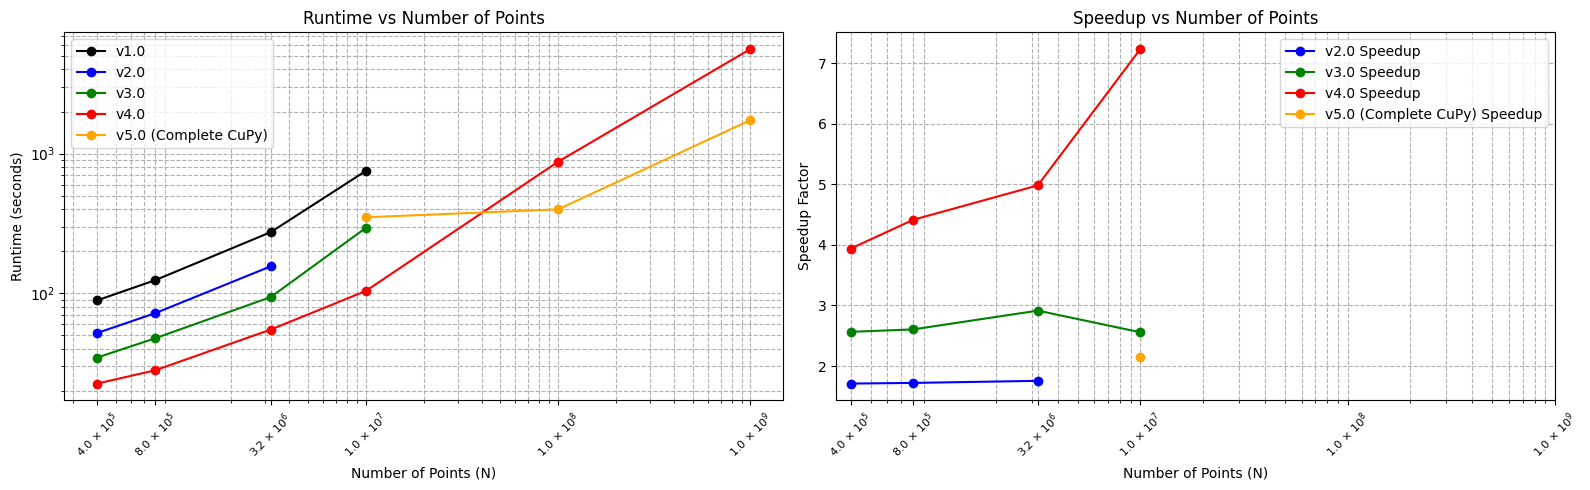

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

f = 7
version_times_vs_n = [
    [400_000, 89, 52, 34.7, 22.6, np.nan],
    [800_000, 124, 72, 47.6, 28.1, np.nan],
    [3_200_000, 274, 156, 94, 55.0, np.nan],
    [10_000_000, 752, np.nan, 294, 104, 600],
    [100_000_000, np.nan, np.nan, np.nan, 125 * f, 57 * f],
    [1_000_000_000, np.nan, np.nan, np.nan, 800 * f, 248 * f],
]
labels = ["N", "v1.0", "v2.0", "v3.0", "v4.0", "v5.0 (Complete CuPy)"]
df = pd.DataFrame(version_times_vs_n, columns=labels)
df["speedup_v2.0"] = df["v1.0"] / df["v2.0"]
df["speedup_v3.0"] = df["v1.0"] / df["v3.0"]
df["speedup_v4.0"] = df["v1.0"] / df["v4.0"]
df["speedup_v5.0 (Complete CuPy)"] = df["v1.0"] / df["v5.0 (Complete CuPy)"]

# Define versions and colors
versions = ["v2.0", "v3.0", "v4.0", "v5.0 (Complete CuPy)"]
colors = ["blue", "green", "red", "orange"]

# Plot subplot of runtimes vs N and speedups vs N
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot v1.0 runtime
ax1.plot(df["N"], df["v1.0"], marker="o", label="v1.0", color="black")

# Loop over versions for runtime
for i, version in enumerate(versions):
    ax1.plot(df["N"], df[version], marker="o", label=version, color=colors[i])

ax1.set_xscale("log")
ax1.set_yscale("log")

# Force specific x-ticks to show
xticks = [4e5, 8e5, 1.6e6, 3.2e6, 6.4e6, 1e7]
xticks = df["N"].tolist()


def x_ticks_helper(vals: list[float]) -> list[str]:
    labels = []
    for x in vals:
        if x == 0:
            labels.append("0")
        else:
            exp = int(np.log10(abs(x)))
            mant = x / (10**exp)
            labels.append(rf"{mant:.1f} $\times$ 10$^{{{exp}}}$")
    return labels


ax1.set_xticks(xticks)
ax1.set_xticklabels(
    x_ticks_helper(xticks),
    rotation=45,
    fontsize=8,
)

ax1.set_xlabel("Number of Points (N)")
ax1.set_ylabel("Runtime (seconds)")
ax1.set_title("Runtime vs Number of Points")
ax1.grid(True, which="both", ls="--")
ax1.legend()

# Loop over versions for speedup
for i, version in enumerate(versions):
    speedup_col = f"speedup_{version}"
    ax2.plot(
        df["N"],
        df[speedup_col],
        marker="o",
        label=f"{version} Speedup",
        color=colors[i],
    )

ax2.set_xscale("log")
ax2.set_xticks(xticks)
ax2.set_xticklabels(
    x_ticks_helper(xticks),
    rotation=45,
    fontsize=8,
)
ax2.set_xlabel("Number of Points (N)")
ax2.set_ylabel("Speedup Factor")
ax2.set_title("Speedup vs Number of Points")
ax2.grid(True, which="both", ls="--")
ax2.legend()

plt.tight_layout()